# Regression and Classification with Toy Data / Hồi quy và phân loại trên dữ liệu mô phỏng

**VI:** Năm bài nhỏ về giá nhà, doanh thu, kết quả học tập, ý định mua hàng và nghỉ việc.
**EN:** Five small examples for housing, revenue, student outcomes, purchase intention and attrition.

Dữ liệu trong notebook được tạo mẫu để luyện thuật toán và đánh giá, không phải dữ liệu kinh doanh thực tế.
The synthetic data are for learning; they are not real operational datasets.

Run cells in order in a Python environment with NumPy, pandas, scikit-learn and Matplotlib.

## Nguồn và cách đọc kết quả / Source and interpretation

Bài thực hành môn học từ Colab `Lab bài tập buổi 8-logistic regression`.
Tôi giữ năm ví dụ và kiểm tra lại thứ tự chạy. Nhãn mô phỏng được tạo từ công thức
có sẵn; metric giúp kiểm tra thuật toán trên công thức đó. Ví dụ giá nhà chỉ có
vài mẫu nên kết quả test dễ thay đổi theo phép chia.

Coursework practice with synthetic targets. Scores describe these small constructed
problems. The housing split is especially small; business use would require new data
and independent validation.

# Hàm vẽ chung cho Linear Regression

In [1]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
np.random.seed(42)
LAB_RESULT = {}

import matplotlib.pyplot as plt

def plot_linear_result(y_test, y_pred, title):
    plt.figure(figsize=(7, 5))

    plt.scatter(y_test, y_pred, alpha=0.8)

    min_value = min(min(y_test), min(y_pred))
    max_value = max(max(y_test), max(y_pred))

    plt.plot([min_value, max_value], [min_value, max_value])

    plt.xlabel("Giá trị thực tế")
    plt.ylabel("Giá trị dự đoán")
    plt.title(title)
    plt.grid(True)
    plt.show()

# Bài 1: Dự đoán giá nhà
Loại: Hồi quy tuyến tính đa biến
Yêu cầu
*   Diện tích
*   Số phòng ngủ
*   Khoảng cách tới trung tâm
*   Tuổi căn nhà

In [2]:
# Import thư viện
import pandas as pd
from sklearn.linear_model import LinearRegression

# -----------------------------
# 1. Tạo dữ liệu mẫu
# -----------------------------
data = {
    'DienTich': [50, 60, 70, 80, 90, 100, 120, 150],
    'SoPhongNgu': [1, 2, 2, 3, 3, 3, 4, 5],
    'KhoangCachTrungTam': [15, 12, 10, 8, 7, 6, 5, 3],
    'TuoiCanNha': [20, 15, 12, 10, 8, 5, 3, 1],
    'GiaNha': [1200, 1500, 1800, 2200, 2600, 3000, 3800, 5000]
}

df = pd.DataFrame(data)

# -----------------------------
# 2. Chia dữ liệu X và y
# -----------------------------
X = df[['DienTich', 'SoPhongNgu', 'KhoangCachTrungTam', 'TuoiCanNha']]
y = df['GiaNha']

# -----------------------------
# 3. Tạo mô hình hồi quy tuyến tính đa biến
# -----------------------------
model = LinearRegression()

# Huấn luyện model
model.fit(X, y)

# -----------------------------
# 4. Dự đoán
# -----------------------------
new_house = pd.DataFrame([[110, 3, 6, 4]], columns=X.columns)

predicted_price = model.predict(new_house)

print("Giá nhà dự đoán:")
print(predicted_price[0])

# -----------------------------
# 5. Hệ số hồi quy
# -----------------------------
print("Các hệ số a:", model.coef_)
print("Hệ số b:", model.intercept_)

Giá nhà dự đoán:
3409.6471257825833
Các hệ số a: [42.91405805  2.10586227 42.71485487 -1.84974388]
Hệ số b: -1566.1070005691536


MAE: 13.598178137651743
MSE: 192.66493695829664
R2 Score: 0.991486186587495

Hệ số hồi quy:
              Feature  Coefficient
0                area     3.497976
1            bedrooms    12.887989
2  distance_to_center    -8.636977
3           house_age    14.257760

Intercept: -234.89878542510127

Giá nhà dự đoán:
273.3670715249662 nghìn USD


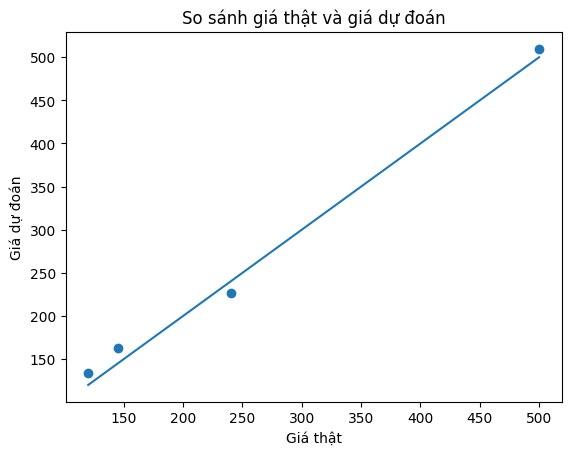

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# =========================
# 1. Tạo dữ liệu mẫu
# =========================

data = {
    "area": [50, 60, 70, 80, 90, 100, 110, 120, 130, 140,
             150, 160, 170, 180, 190, 200],
    "bedrooms": [1, 2, 2, 2, 3, 3, 3, 4, 4, 4,
                 4, 5, 5, 5, 6, 6],
    "distance_to_center": [12, 11, 10, 9, 8, 8, 7, 7, 6, 6,
                           5, 5, 4, 4, 3, 3],
    "house_age": [20, 18, 15, 14, 12, 10, 9, 8, 7, 6,
                  5, 4, 3, 3, 2, 1],
    "price": [120, 145, 165, 190, 220, 240, 265, 290, 315, 340,
              370, 400, 430, 460, 500, 540]
}

df = pd.DataFrame(data)

# =========================
# 2. Tách biến đầu vào và đầu ra
# =========================

X = df[["area", "bedrooms", "distance_to_center", "house_age"]]
y = df["price"]

# =========================
# 3. Chia dữ liệu train/test
# =========================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# =========================
# 4. Huấn luyện mô hình
# =========================

model = LinearRegression()
model.fit(X_train, y_train)

# =========================
# 5. Dự đoán trên tập test
# =========================

y_pred = model.predict(X_test)

# =========================
# 6. Đánh giá mô hình
# =========================

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

# =========================
# 7. Xem hệ số hồi quy
# =========================

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print("\nHệ số hồi quy:")
print(coefficients)

print("\nIntercept:", model.intercept_)

# =========================
# 8. Dự đoán giá nhà mới
# =========================

new_house = pd.DataFrame({
    "area": [125],
    "bedrooms": [4],
    "distance_to_center": [6],
    "house_age": [5]
})

predicted_price = model.predict(new_house)

print("\nGiá nhà dự đoán:")
print(predicted_price[0], "nghìn USD")

# =========================
# 9. Vẽ biểu đồ giá thật và giá dự đoán
# =========================

plt.scatter(y_test, y_pred)
plt.xlabel("Giá thật")
plt.ylabel("Giá dự đoán")
plt.title("So sánh giá thật và giá dự đoán")

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])

plt.show()
LAB_RESULT["housing_test_r2"] = float(r2)


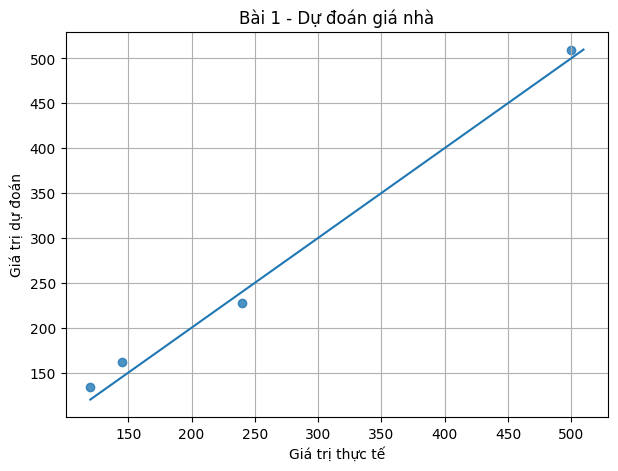

In [4]:
plot_linear_result(y_test, y_pred, "Bài 1 - Dự đoán giá nhà")

#Bài 2: Dự đoán doanh thu cửa hàng
Loại: Hồi quy tuyến tính đa biến

Yêu cầu
Dự đoán doanh thu dựa vào:
•	Chi phí quảng cáo Facebook

*   Chi phí quảng cáo Google
*   Số nhân viên bán hàng
*   Số khách ghé cửa hàng

In [5]:
# =========================
# Bài 2: Dự đoán doanh thu cửa hàng
# Linear Regression
# =========================

n = 200

facebook_ads = np.random.uniform(1, 50, n)       # triệu VND
google_ads = np.random.uniform(1, 60, n)         # triệu VND
employees = np.random.randint(1, 20, n)
visitors = np.random.randint(50, 2000, n)

revenue = (
    facebook_ads * 8
    + google_ads * 10
    + employees * 15
    + visitors * 0.25
    + np.random.normal(0, 50, n)
)

df_revenue = pd.DataFrame({
    "chi_phi_facebook": facebook_ads,
    "chi_phi_google": google_ads,
    "so_nhan_vien": employees,
    "so_khach_ghe": visitors,
    "doanh_thu": revenue
})

df_revenue.head()

,chi_phi_facebook,chi_phi_google,so_nhan_vien,so_khach_ghe,doanh_thu
0,19.352466,38.879867,9,1554,1055.170995
1,47.585001,5.964258,17,1033,908.194404
2,36.867703,10.536094,17,1408,978.464000
3,30.334266,54.014697,16,1069,1327.840658
4,8.644913,36.779315,13,591,804.748312


In [6]:
X = df_revenue[["chi_phi_facebook", "chi_phi_google", "so_nhan_vien", "so_khach_ghe"]]
y = df_revenue["doanh_thu"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_revenue = LinearRegression()
model_revenue.fit(X_train, y_train)

y_pred = model_revenue.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

sample = pd.DataFrame({
    "chi_phi_facebook": [20],
    "chi_phi_google": [30],
    "so_nhan_vien": [8],
    "so_khach_ghe": [1000]
})

print("Doanh thu dự đoán:", model_revenue.predict(sample)[0])

LAB_RESULT["revenue_test_r2"] = float(r2_score(y_test, y_pred))


MAE: 34.957886156270135
RMSE: 44.44228215179604
R2: 0.9758977859187503
Doanh thu dự đoán: 826.0923679353735


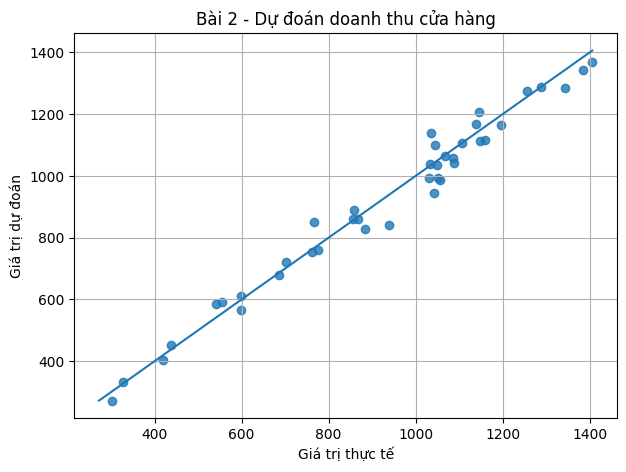

In [7]:
plot_linear_result(y_test, y_pred, "Bài 2 - Dự đoán doanh thu cửa hàng")

# **Logistic Regression**




# Hàm vẽ chung cho Logistic Regression

# Bài 3: Dự đoán học sinh đậu hay rớt
Loại: Hồi quy logistic đa biến
Yêu cầu
Dự đoán học sinh có đậu hay không dựa vào:
*   Số giờ học
*   Điểm chuyên cần
*   Điểm giữa kỳ

In [8]:
def plot_logistic_result(y_test, y_prob, title):
    plt.figure(figsize=(8, 5))

    probabilities = y_prob[:, 1]

    plt.scatter(range(len(probabilities)), probabilities, label="Xác suất dự đoán")
    plt.axhline(y=0.5, linestyle="--", label="Ngưỡng 0.5")

    plt.xlabel("Mẫu dữ liệu")
    plt.ylabel("Xác suất thuộc lớp 1")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [9]:
# =========================
# Bài 3: Dự đoán học sinh đậu/rớt
# Logistic Regression
# =========================

n = 200

study_hours = np.random.uniform(0, 10, n)
attendance = np.random.uniform(40, 100, n)
midterm_score = np.random.uniform(0, 10, n)

score = (
    study_hours * 0.5
    + attendance * 0.04
    + midterm_score * 0.8
    + np.random.normal(0, 1, n)
)

passed = (score >= 8).astype(int)

df_student = pd.DataFrame({
    "so_gio_hoc": study_hours,
    "diem_chuyen_can": attendance,
    "diem_giua_ky": midterm_score,
    "dau": passed
})

df_student.head()

,so_gio_hoc,diem_chuyen_can,diem_giua_ky,dau
0,7.636058,55.936003,0.816300,0
1,1.401132,47.770895,0.603521,0
2,8.684680,93.324885,2.471032,1
3,4.874312,97.339090,1.595447,0
4,8.945522,91.727657,8.717836,1


In [10]:
X = df_student[["so_gio_hoc", "diem_chuyen_can", "diem_giua_ky"]]
y = df_student["dau"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_student = LogisticRegression()
model_student.fit(X_train, y_train)

y_pred = model_student.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

sample = pd.DataFrame({
    "so_gio_hoc": [6],
    "diem_chuyen_can": [85],
    "diem_giua_ky": [7]
})

print("Dự đoán đậu/rớt:", model_student.predict(sample)[0])
print("Xác suất:", model_student.predict_proba(sample))
LAB_RESULT["student_test_accuracy"] = float(accuracy_score(y_test, y_pred))


Accuracy: 0.875
[[12  2]
 [ 3 23]]
              precision    recall  f1-score   support

           0       0.80      0.86      0.83        14
           1       0.92      0.88      0.90        26

    accuracy                           0.88        40
   macro avg       0.86      0.87      0.86        40
weighted avg       0.88      0.88      0.88        40

Dự đoán đậu/rớt: 1
Xác suất: [[6.04848621e-04 9.99395151e-01]]


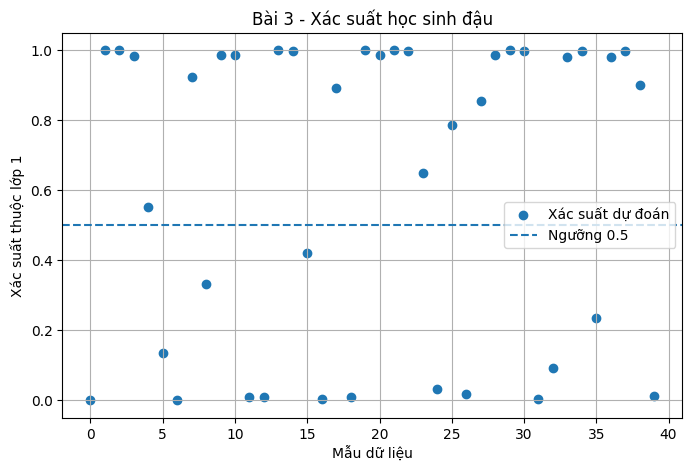

In [11]:
y_prob = model_student.predict_proba(X_test)

plot_logistic_result(
    y_test,
    y_prob,
    "Bài 3 - Xác suất học sinh đậu"
)

# Bài 4: Dự đoán khách hàng có mua sản phẩm hay không
Loại: Hồi quy logistic đa biến
Yêu cầu
Dự đoán khách hàng có mua hàng không dựa vào:
*   Tuổi
*   Thu nhập
*   Thời gian xem sản phẩm
*   Số lần click quảng cáo

In [12]:
# =========================
# Bài 4: Dự đoán khách hàng có mua hàng không
# Logistic Regression
# =========================

n = 200

age = np.random.randint(18, 65, n)
income = np.random.uniform(5, 100, n)             # triệu VND/tháng
view_time = np.random.uniform(1, 300, n)          # giây
ad_clicks = np.random.randint(0, 20, n)

buy_score = (
    income * 0.04
    + view_time * 0.015
    + ad_clicks * 0.25
    - age * 0.02
    + np.random.normal(0, 1, n)
)

bought = (buy_score >= 5).astype(int)

df_customer = pd.DataFrame({
    "tuoi": age,
    "thu_nhap": income,
    "thoi_gian_xem_sp": view_time,
    "so_lan_click_qc": ad_clicks,
    "mua_hang": bought
})

df_customer.head()

,tuoi,thu_nhap,thoi_gian_xem_sp,so_lan_click_qc,mua_hang
0,58,56.176088,59.556403,6,0
1,46,54.795121,269.190421,16,1
2,46,85.564540,156.536966,9,1
3,55,84.796578,134.833279,10,1
4,59,84.104645,167.788237,8,1


In [13]:
X = df_customer[["tuoi", "thu_nhap", "thoi_gian_xem_sp", "so_lan_click_qc"]]
y = df_customer["mua_hang"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_customer = LogisticRegression(max_iter=1000)
model_customer.fit(X_train, y_train)

y_pred = model_customer.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

sample = pd.DataFrame({
    "tuoi": [30],
    "thu_nhap": [35],
    "thoi_gian_xem_sp": [180],
    "so_lan_click_qc": [8]
})

print("Dự đoán mua hàng:", model_customer.predict(sample)[0])
print("Xác suất:", model_customer.predict_proba(sample))
LAB_RESULT["purchase_test_accuracy"] = float(accuracy_score(y_test, y_pred))


Accuracy: 0.85
[[11  4]
 [ 2 23]]
              precision    recall  f1-score   support

           0       0.85      0.73      0.79        15
           1       0.85      0.92      0.88        25

    accuracy                           0.85        40
   macro avg       0.85      0.83      0.84        40
weighted avg       0.85      0.85      0.85        40

Dự đoán mua hàng: 1
Xác suất: [[0.3412803 0.6587197]]


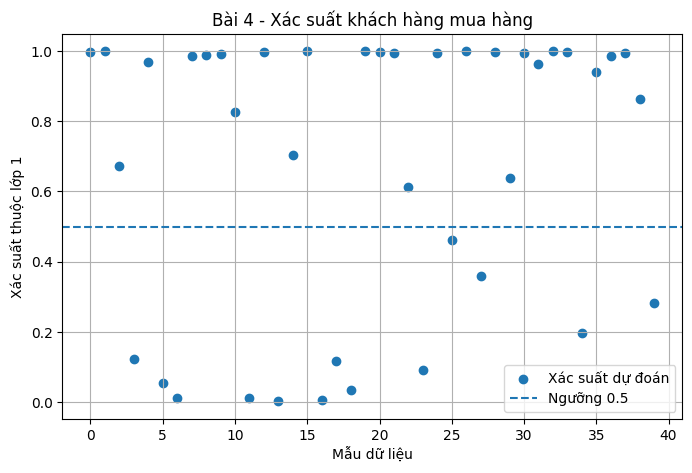

In [14]:
y_prob = model_customer.predict_proba(X_test)

plot_logistic_result(
    y_test,
    y_prob,
    "Bài 4 - Xác suất khách hàng mua hàng"
)

# Bài 5: Dự đoán nhân viên có nghỉ việc hay không
Loại: Hồi quy logistic đa biến
Yêu cầu
Dự đoán nhân viên có nghỉ việc không dựa vào:
*   Mức lương
*   Số năm kinh nghiệm
*   Mức độ hài lòng
*   Số giờ làm thêm

In [15]:
# =========================
# Bài 5: Dự đoán nhân viên nghỉ việc
# Logistic Regression
# =========================

n = 200

salary = np.random.uniform(6, 80, n)              # triệu VND/tháng
experience = np.random.uniform(0, 20, n)          # năm
satisfaction = np.random.uniform(1, 10, n)        # mức hài lòng
overtime = np.random.uniform(0, 60, n)            # giờ overtime/tháng

quit_score = (
    - salary * 0.05
    - experience * 0.08
    - satisfaction * 0.7
    + overtime * 0.08
    + np.random.normal(0, 1, n)
)

quit_job = (quit_score >= -5).astype(int)

df_employee = pd.DataFrame({
    "muc_luong": salary,
    "so_nam_kinh_nghiem": experience,
    "muc_do_hai_long": satisfaction,
    "so_gio_lam_them": overtime,
    "nghi_viec": quit_job
})

df_employee.head()

,muc_luong,so_nam_kinh_nghiem,muc_do_hai_long,so_gio_lam_them,nghi_viec
0,44.329079,0.029476,3.178199,39.403769,1
1,31.759074,14.586896,7.426475,42.525939,1
2,33.508708,19.336910,1.822523,0.501821,0
3,6.100168,4.485870,2.793433,13.060044,1
4,28.185239,13.260944,8.897230,39.701057,0


In [16]:
X = df_employee[["muc_luong", "so_nam_kinh_nghiem", "muc_do_hai_long", "so_gio_lam_them"]]
y = df_employee["nghi_viec"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_employee = LogisticRegression(max_iter=1000)
model_employee.fit(X_train, y_train)

y_pred = model_employee.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

sample = pd.DataFrame({
    "muc_luong": [15],
    "so_nam_kinh_nghiem": [2],
    "muc_do_hai_long": [4],
    "so_gio_lam_them": [35]
})

print("Dự đoán nghỉ việc:", model_employee.predict(sample)[0])
print("Xác suất:", model_employee.predict_proba(sample))
LAB_RESULT["attrition_test_accuracy"] = float(accuracy_score(y_test, y_pred))


Accuracy: 0.875
[[15  4]
 [ 1 20]]
              precision    recall  f1-score   support

           0       0.94      0.79      0.86        19
           1       0.83      0.95      0.89        21

    accuracy                           0.88        40
   macro avg       0.89      0.87      0.87        40
weighted avg       0.88      0.88      0.87        40

Dự đoán nghỉ việc: 1
Xác suất: [[6.55253651e-05 9.99934475e-01]]


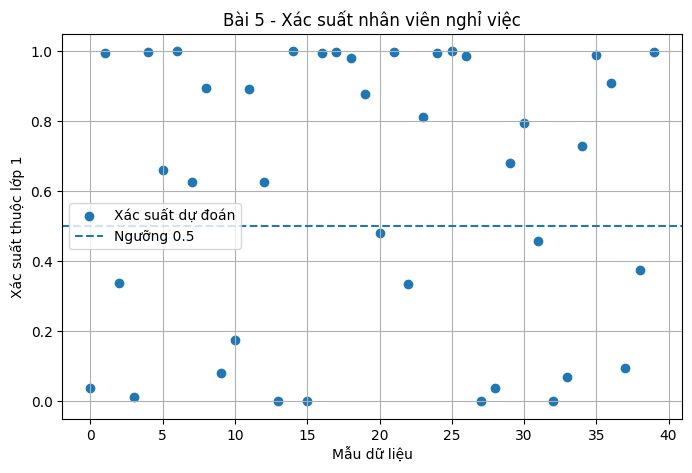

In [17]:
y_prob = model_employee.predict_proba(X_test)

plot_logistic_result(
    y_test,
    y_prob,
    "Bài 5 - Xác suất nhân viên nghỉ việc"
)

In [18]:
assert all(np.isfinite(value) for value in LAB_RESULT.values())
# Các lớp đều xuất hiện trong từng bài phân loại / Each classification task has two classes.
for fitted_model in (model_student, model_customer, model_employee):
    assert set(fitted_model.classes_) == {0, 1}
print('Toy-lab results:', LAB_RESULT)

Toy-lab results: {'housing_test_r2': 0.991486186587495, 'revenue_test_r2': 0.9758977859187503, 'student_test_accuracy': 0.875, 'purchase_test_accuracy': 0.85, 'attrition_test_accuracy': 0.875}
